# 新矩形翼：10–15 Hz 升力与实测对比

单左翼，保留双侧传动；frame 和原翼根为 PET，10 μm Kapton 膜，CNC PEEK 机构。
本 Notebook 读取实际完成的仿真，重新积分每档升力并核对原始数据哈希。
实测误差棒为每档 3 次记录的样本 SD。模型未按实测升力拟合。


In [1]:
from pathlib import Path
import sys, json, hashlib
import numpy as np
from IPython.display import display, Image, Markdown
FOLDER = Path.cwd()
ROOT = FOLDER.parents[1]
sys.path.insert(0, str(ROOT/'experiments/fixbase'))
from run_15hz import cycle_statistics
OUT = FOLDER/'rect_material_validation'
results = json.loads((OUT/'simulation_summary.json').read_text())
rows = json.loads((OUT/'lift_comparison.json').read_text())
assert sorted(r['nominal_hz'] for r in results) == list(range(10,16))
for r in results:
    data = dict(np.load(OUT/r['source']))
    stats = cycle_statistics(data, target_hz=r['target_wing_frequency_hz'])
    np.testing.assert_allclose(stats['mean_lift_N'], r['mean_lift_N'], rtol=1e-13)
    assert abs(stats['measured_wing_frequency_hz']-r['target_wing_frequency_hz']) < .01
    assert not any(r['numerical_warnings']) and r['max_base_pose_error'] == 0
    assert hashlib.sha256(Path(r['simulation']['model_path']).read_bytes()).hexdigest() == r['model_sha256']
for record in json.loads((OUT/'source_manifest.json').read_text()):
    assert hashlib.sha256((FOLDER/record['path']).read_bytes()).hexdigest() == record['sha256']
print('六档升力重新积分一致；频率、基座、模型和原始数据哈希核对通过。')

六档升力重新积分一致；频率、基座、模型和原始数据哈希核对通过。


|档位 Hz|实测 ± SD (mN)|仿真 (mN)|相对误差|
|---:|---:|---:|---:|
|10|25.934 ± 0.419|19.532|-24.69%|
|11|31.676 ± 0.727|23.979|-24.30%|
|12|36.157 ± 0.572|27.971|-22.64%|
|13|44.401 ± 2.092|33.096|-25.46%|
|14|51.317 ± 0.794|37.660|-26.61%|
|15|59.315 ± 1.544|43.264|-27.06%|

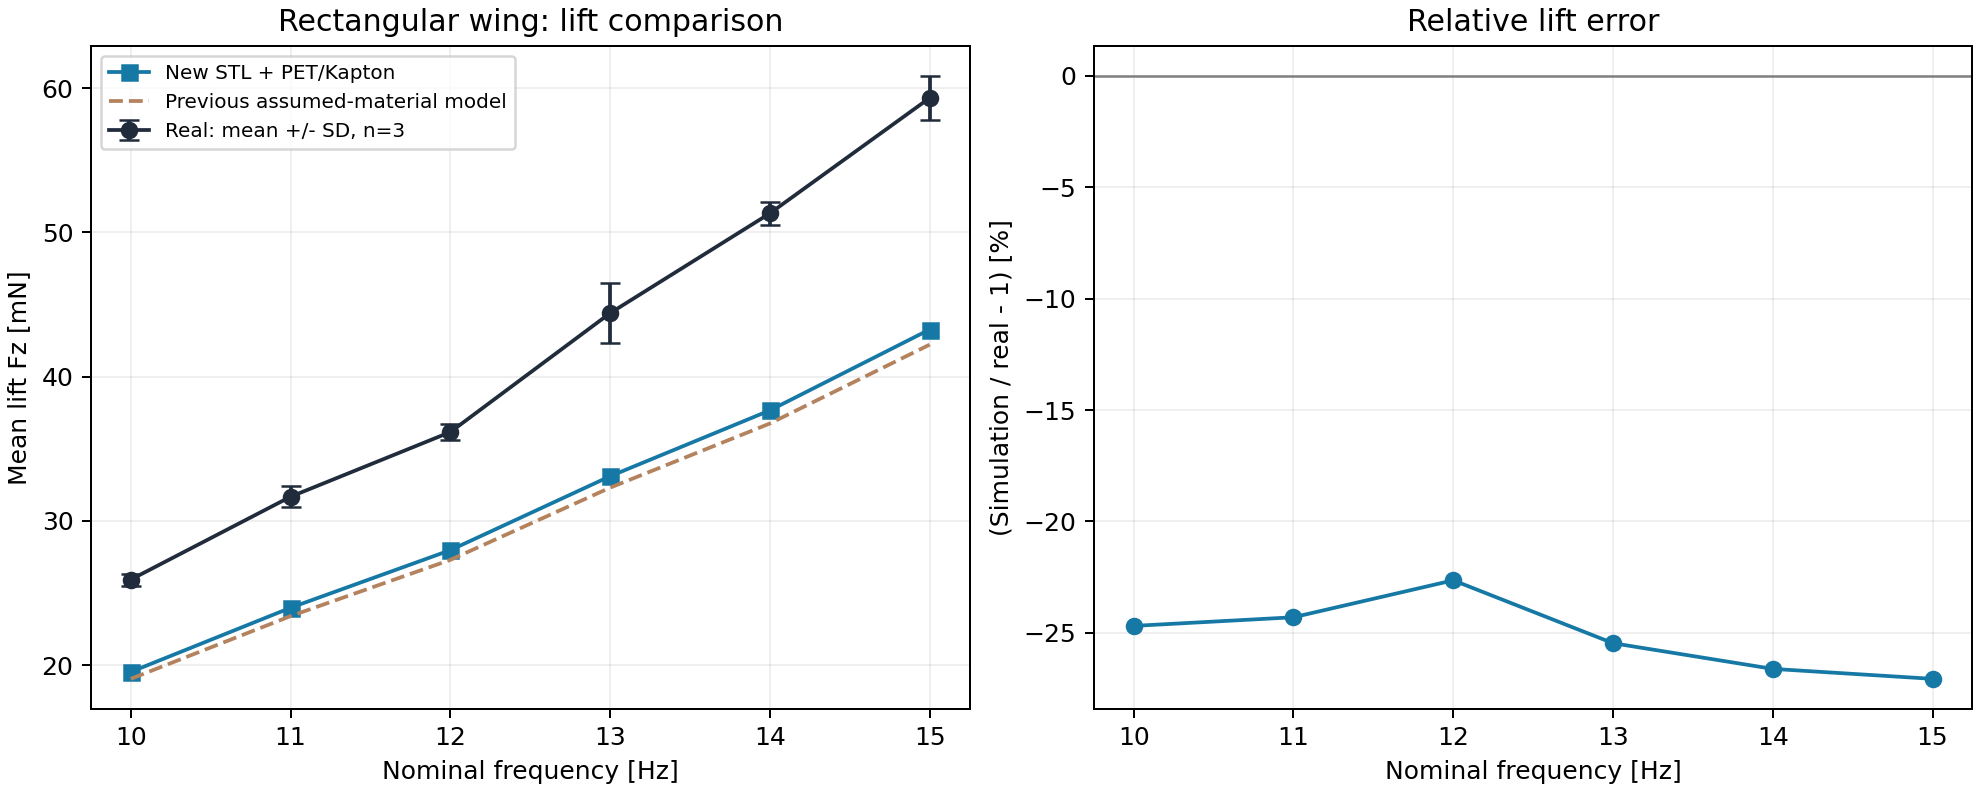

In [2]:
table = ['|档位 Hz|实测 ± SD (mN)|仿真 (mN)|相对误差|', '|---:|---:|---:|---:|']
for r in rows:
    table.append(f"|{r['hz']}|{r['real_lift_mN']:.3f} ± {r['real_sd_mN']:.3f}|{r['simulation_lift_mN']:.3f}|{r['relative_error_pct']:+.2f}%|")
display(Markdown(chr(10).join(table)))
display(Image(filename=str(OUT/'lift_comparison.png')))

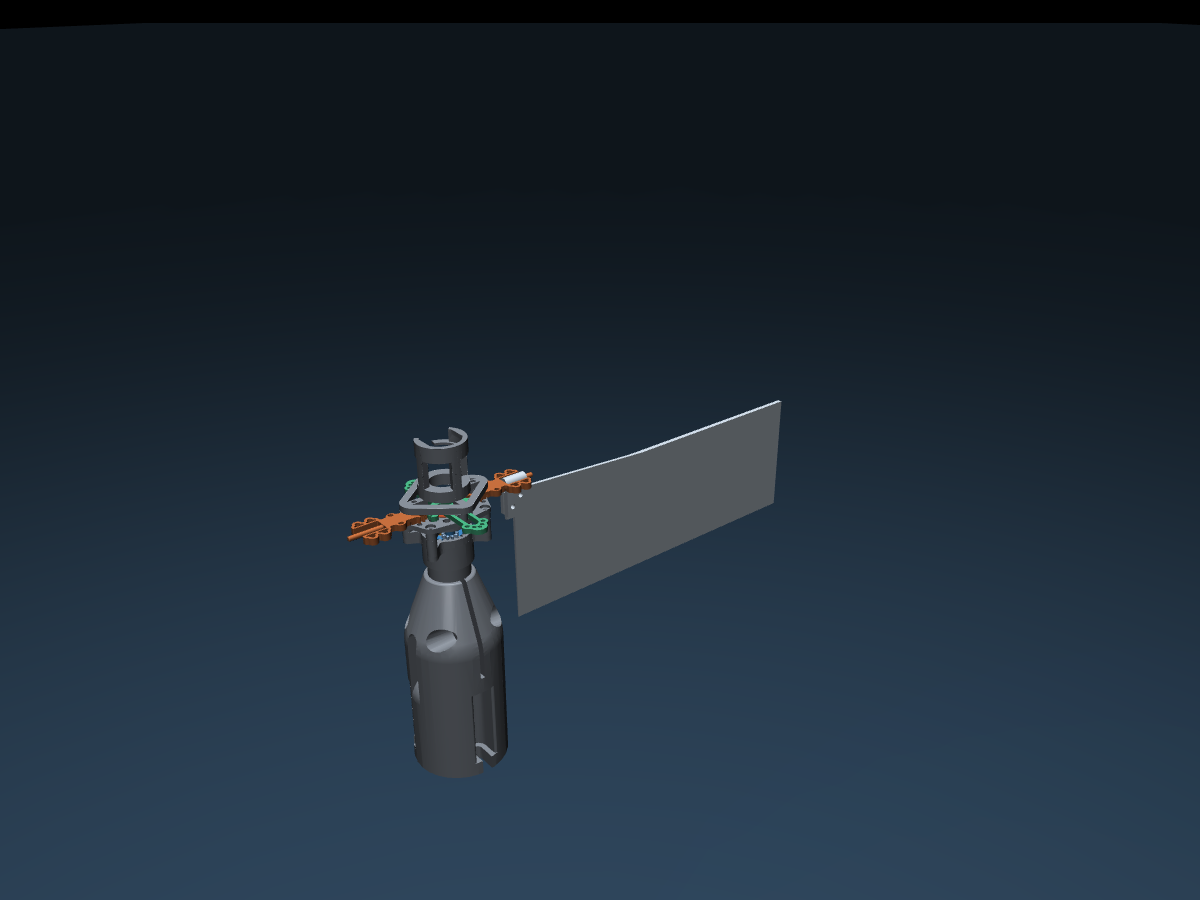

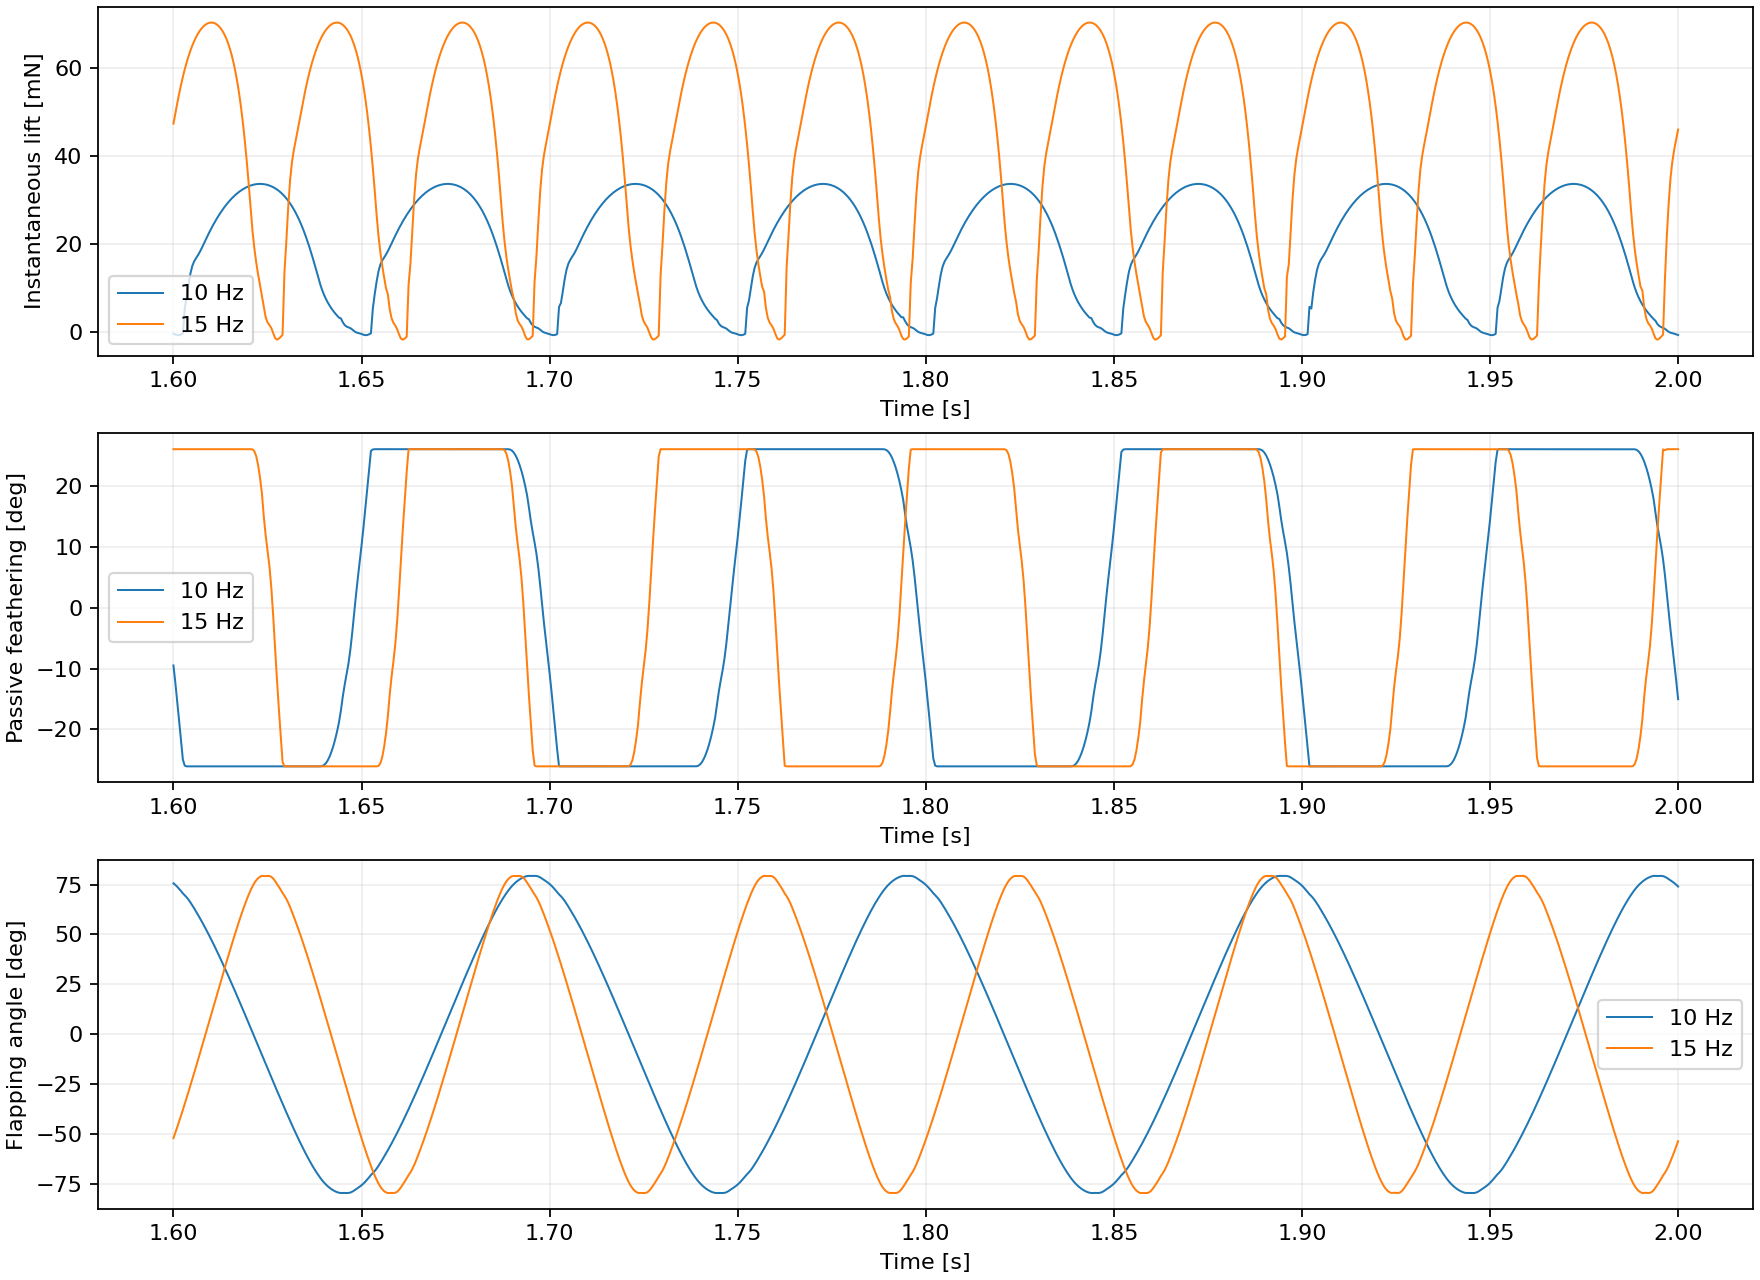

In [3]:
display(Image(filename=str(OUT/'rectangular_model.png')))
display(Image(filename=str(OUT/'steady_waveforms.png')))

In [4]:
meta = json.loads((OUT/'model_assumptions.json').read_text())
for key in ('frame_mass_kg','root_connector_mass_kg','membrane_mass_kg','mass_kg'):
    print(key, f"{meta[key]*1e6:.3f} mg")
checks = json.loads((OUT/'convergence_summary.json').read_text())
for r in checks:
    print(r['simulation']['fluid']['strips'], 'strips;', r['simulation']['scene']['timestep'],
          's/step;', f"{r['mean_lift_mN']:.4f} mN")

frame_mass_kg 248.816 mg
root_connector_mass_kg 79.425 mg
membrane_mass_kg 29.555 mg
mass_kg 357.796 mg
24 strips; 5e-06 s/step; 43.2851 mN
12 strips; 2.5e-06 s/step; 43.2660 mN


完整方法、限制及统计检查见 `rect_material_validation/report.md`。
仿真按实测编码器频率校准电机指令；实测采用 0.5–4.0 s 均值并减去 5.5 s 后尾段基线。
升力残差不能单独确定气动模型、翼膜柔性或羽化运动中的哪一项造成偏差。

重新运行实验：
```bash
python experiments/fixbase_curved_real/rect_material_experiment.py --prepare --run --convergence --report
python experiments/fixbase_curved_real/rect_material_notebook.py
```